# UCS420 Lab Assignment 9 — NLP Text Preprocessing
**Name:** Jatin Kumar  |  **Roll No.:** 1024170438

Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170438          # <-- your full roll number
NAME = "Jatin Kumar"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170438   Name: Jatin Kumar   Fingerprint: 27E38D6A   Tickets: 15

Ticket_ID                                                                    Ticket_Text
      T01                   The student portal has stopped syncing. It worked yesterday.
      T02                  Password is not working since yesterday. It worked yesterday.
      T03                                           Python 3.12 was installed yesterday.
      T04   I was locked out of the Python while uploading the file. Can you check this?
      T05              The printer crashes while opening. The same problem occurs again.
      T06     WiFi stopped responding when connected to campus Wi-Fi. Please resolve it.
      T07                    The printer keeps disconnecting. Is there another solution?
      T08                 The wifi keeps asking for login. It works on another computer.
      T09                                                  The LMS says 'Not Submitted'.
      T10                  

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
import pandas as pd
from IPython.display import display

results, rows = {}, []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    r = process_ticket(text)
    results[tid] = r
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punctuation": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique_Tokens": len(set(r["tokens"])),
        "Final_Tokens": len(r["final"]),
    })
    # sanity check: every token is exactly one of punctuation / stopword / final
    assert len(r["tokens"]) == len(r["punct"]) + len(r["stops"]) + len(r["final"])

q1 = pd.DataFrame(rows)
total = {"Ticket_ID": "TOTAL"}
for col in ["Sentences", "Tokens", "Punctuation", "Stopwords", "Final_Tokens"]:
    total[col] = int(q1[col].sum())
# TOTAL for Unique_Tokens = distinct tokens across the WHOLE dataset (a plain sum would double count repeats)
total["Unique_Tokens"] = len({t for r in results.values() for t in r["tokens"]})
q1 = pd.concat([q1, pd.DataFrame([total])], ignore_index=True)
print(q1.to_string(index=False))

print("\nFinal tokens per ticket:")
for tid, r in results.items():
    print(tid, r["final"])

# --- for the Observe question: final tokens that are not real words
non_words = {}
for tid, r in results.items():
    for t in r["final"]:
        if not t.isalpha() or t in {"n't", "ca", "wo", "'s"}:
            non_words.setdefault(t, []).append(tid)
print("\nNon-word / odd final tokens -> tickets:")
for t, tids in non_words.items():
    print(f"  {t!r:12} {tids}")

# --- one selected ticket: show the actual tokens, punctuation, stopwords and final tokens
SELECTED = "T14"          # chosen because it has contractions (won't, isn't)
r = results[SELECTED]
print(f"\nSelected ticket {SELECTED}: {df.loc[df.Ticket_ID == SELECTED, 'Ticket_Text'].iloc[0]}")
print("tokens     :", r["tokens"])
print("punctuation:", r["punct"])
print("stopwords  :", r["stops"])
print("final      :", r["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      11            2          3             10             6
      T02          2      11            2          3              9             6
      T03          1       6            1          1              6             4
      T04          2      17            2         10             16             5
      T05          2      12            2          5             10             5
      T06          2      13            2          3             12             8
      T07          2      10            2          3             10             5
      T08          2      13            2          4             12             7
      T09          1       8            3          2              7             3
      T10          2       8            2          1              7             5
      T11          2      16            2          6             14             8
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In my data the broken tokens are `wo` and `n't` (n't comes twice). Both are from ticket T14, "The printer won't print; it isn't jammed." word_tokenize splits contractions, so "won't" becomes `wo` + `n't` and "isn't" becomes `is` + `n't`. The NLTK stopword list has full forms like "isn't" and "won't" but not the pieces `n't` or `wo`, so only `is` got removed and the pieces stayed. (`ca` and `'s` would come from "can't" and "Rao's" in the same way, but they are not in my tickets.) Tokens like `3.12`, `1023-03-021` and `wi-fi` are not dictionary words either, but they are valid tokens.

One more thing I noticed: `not` is a stopword, so "is not working" (T02) became `working` and "Not Submitted" (T09) became `submitted`. The meaning gets reversed.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# ---------- extraction patterns ----------
LONG_WORD = r"\b[A-Za-z]{6,}\b"                                   # words longer than 5 letters
NUMBER    = r"\d+(?:[.,]\d+)*"                                     # 95.5, 2.0.1, 1,250, 5.30 stay whole
CAPITAL   = r"\b[A-Z][A-Za-z]*(?:-[A-Za-z]+)*\b"                   # starts with a capital (Python, LMS, Wi-Fi)
VOWEL     = r"\b[AEIOUaeiou][A-Za-z']*\b"                          # words starting with a vowel

# ---------- masking patterns (applied in this order: EMAIL -> URL -> PHONE) ----------
EMAIL = r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b"
URL   = r"(?:https?://|www\.)[^\s<>\"']+?(?=[.,;:!?]*(?:\s|$))"    # lazy, so a trailing '.' is not swallowed
PHONE = r"(?<!\w)(?:(?:\+\d{1,3}[\s-]?)?\d{5}[\s-]?\d{5}|0\d{3,4}-\d{3}-\d{4})(?!\w)"

def mask(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL, "<URL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

def extract_all(text):
    return {
        "long_words": re.findall(LONG_WORD, text),
        "numbers":    re.findall(NUMBER, text),
        "capitalized": re.findall(CAPITAL, text),
        "vowel_words": re.findall(VOWEL, text),
    }

# ---------- 1) on the raw tickets ----------
print("=== RAW TICKETS ===")
agg = {k: [] for k in ["long_words", "numbers", "capitalized", "vowel_words"]}
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    res = extract_all(text)
    for k in agg: agg[k].extend(res[k])
    print(f"{tid}: {text}")
    print(f"     long>5  : {res['long_words']}")
    print(f"     numbers : {res['numbers']}")
    print(f"     capital : {res['capitalized']}")
    print(f"     vowel   : {res['vowel_words']}")
    print(f"     masked  : {mask(text)}")
print("\nTotals:", {k: len(v) for k, v in agg.items()})

# ---------- 2) on TEST_LINES ----------
print("\n=== TEST_LINES ===")
for line in TEST_LINES:
    res = extract_all(line)
    print("LINE   :", line)
    for k, v in res.items():
        print(f"  {k:12}: {v}")
    print("  MASKED :", mask(line), "\n")

# ---------- for the Observe question ----------
sent_start, total_caps = 0, 0
for text in df["Ticket_Text"]:
    for m in re.finditer(CAPITAL, text):
        total_caps += 1
        before = text[:m.start()]
        if before.strip() == "" or re.search(r"[.!?]\s*$", before):
            sent_start += 1
print(f"Capitalized words: {total_caps} | capitalized only because they start a sentence: {sent_start}")

=== RAW TICKETS ===
T01: The student portal has stopped syncing. It worked yesterday.
     long>5  : ['student', 'portal', 'stopped', 'syncing', 'worked', 'yesterday']
     numbers : []
     capital : ['The', 'It']
     vowel   : ['It']
     masked  : The student portal has stopped syncing. It worked yesterday.
T02: Password is not working since yesterday. It worked yesterday.
     long>5  : ['Password', 'working', 'yesterday', 'worked', 'yesterday']
     numbers : []
     capital : ['Password', 'It']
     vowel   : ['is', 'It']
     masked  : Password is not working since yesterday. It worked yesterday.
T03: Python 3.12 was installed yesterday.
     long>5  : ['Python', 'installed', 'yesterday']
     numbers : ['3.12']
     capital : ['Python']
     vowel   : ['installed']
     masked  : Python 3.12 was installed yesterday.
T04: I was locked out of the Python while uploading the file. Can you check this?
     long>5  : ['locked', 'Python', 'uploading']
     numbers : []
     capital :

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* I got 32 capitalized words in total, and 26 of them are capitalized only because they begin a sentence (The, It, Please, Can, Is, My, etc.). Only 6 are capitalized for a real reason: Python (T04), Wi-Fi (T06), LMS and "Not Submitted" (T09), and VPN (T15). So checking capital letters alone is not a good way to find names, since most capitals are just sentence starts.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

TOKEN_PATTERN = "|".join([
    r"(?:https?://|www\.)[^\s<>\"']+?(?=[.,;:!?]*(?:\s|$))",          # 1 URL
    r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",                                   # 2 email
    r"(?:\+\d{1,3}[\s-]?)?\d{5}[\s-]?\d{5}|0\d{3,4}-\d{3}-\d{4}",      # 3 phone
    r"(?:[A-Za-z]\.){2,}",                                             # 4 abbreviations: p.m., a.m.
    r"\d+(?:[.,]\d+)+",                                                # 5 decimals / versions: 95.5, 2.0.1, 1,250
    r"[A-Za-z0-9]+(?:[-'’][A-Za-z0-9]+)*",                             # 6 words: isn't, Wi-Fi, state-of-the-art, 0x80070005
    r"\.{2,}|!{2,}|\?{2,}|[^\w\s]",                                    # 7 punctuation kept as its own token
])
_tok = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _tok.tokenize(text)

# ---------- TEST_LINES ----------
for line in TEST_LINES:
    print("LINE        :", line)
    print("my_tokenize :", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line), "\n")

# ---------- tickets ----------
diff = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    a, b = my_tokenize(text), word_tokenize(text)
    if a != b:
        diff.append(tid)
        print(f"{tid}: {text}")
        print("   my_tokenize  :", a)
        print("   word_tokenize:", b)
        print("   only in mine :", [t for t in a if t not in b], "| only in NLTK:", [t for t in b if t not in a])
print(f"\nTickets tokenized differently: {len(diff)} of {len(df)} -> {diff}")

LINE        : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.'] 

LINE        : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.'] 

LINE        : The state-of-the-art lab isn't open; log-in at 5.30 p

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* Only 1 out of 15 tickets is different, which is T14. my_tokenize keeps "won't" and "isn't" as single tokens, while word_tokenize gives `wo`, `n't` and `is`, `n't`. The other tickets are the same because they only have plain words, hyphens, decimals and normal punctuation. The big difference shows in TEST_LINES: word_tokenize cuts emails at `@`, cuts the URL at the colon and splits the phone number `+91 98765 43210` into three tokens, but my_tokenize keeps each of them as one token.

**Differences between `my_tokenize` and `word_tokenize` (seen in the output above):**
1. **Email addresses:** `word_tokenize` splits `it.helpdesk@thapar.edu` into `it.helpdesk`, `@`, `thapar.edu`. `my_tokenize` keeps the whole address as one token because the email alternative comes first in the pattern.
2. **URLs:** `word_tokenize` breaks `https://lms.thapar.edu/help` into `https`, `:` and `//lms.thapar.edu/help`. `my_tokenize` keeps the full URL as one token (and the full stop at the end of the sentence is not taken into the URL).
3. **Phone numbers with spaces:** `+91 98765 43210` becomes three tokens (`+91`, `98765`, `43210`) in `word_tokenize`, but one token in `my_tokenize`. (Phone numbers written with hyphens, like `0175-239-3201`, stay whole in both.)
4. **Contractions:** `word_tokenize` follows Treebank rules and splits `isn't` → `is`, `n't`, `didn't` → `did`, `n't` and `won't` → `wo`, `n't`. `my_tokenize` keeps `isn't`, `didn't`, `won't` whole, as the assignment asks.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

**Why I chose the Regexp suffix rule `ing$|ed$|s$` (with `min=4`):** I looked at the unique final tokens of my own dataset and saw three common endings.
- **`-ing`:** `disconnecting`, `responding`, `syncing`, `opening`, `uploading`, `restarting` (6 words in my data).
- **`-ed`:** `stopped`, `worked`, `locked`, `jammed`, `installed`, `connected`.
- **`-s`:** `keeps`, `works`, `crashes`, `times`, `says` (verbs in the present tense and plurals).

So one rule removes the three most frequent inflection endings in my tickets. `min=4` stops very short words such as `lms` or `vpn` from being cut. The weak points are visible in the table: it cannot fix doubled letters (`stopped → stopp`, `jammed → jamm`) and it cuts the `-s` of words that are not plurals (`campus → campu`).

In [8]:
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

# unique final tokens (sorted, only the ones that are real alphabetic words -> clean stem/lemma comparison)
# POS tags are taken IN CONTEXT (whole lowercase ticket), because pos_tag on a lone word is unreliable
pos_of = {}
for tid, r in results.items():
    for tok, tag in pos_tag(r["tokens"]):
        if tok in r["final"] and tok not in pos_of:
            pos_of[tok] = tag
unique_final = sorted({t for r in results.values() for t in r["final"]})
print(len(unique_final), "unique final tokens:", unique_final)

def to_wn(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

porter, lancaster, lemm = PorterStemmer(), LancasterStemmer(), WordNetLemmatizer()
# Rule chosen after looking at the words above: tickets are full of -ing / -ed / -s forms
# (disconnecting, responding, stopped, syncing, errors, ...), so strip exactly those suffixes.
regexp = RegexpStemmer(r"ing$|ed$|s$", min=4)

rows = []
for w in unique_final:
    rows.append({"Word": w, "POS": pos_of[w],
                 "Porter": porter.stem(w), "Lancaster": lancaster.stem(w),
                 "Regexp": regexp.stem(w), "Lemma": lemm.lemmatize(w, to_wn(pos_of[w]))})
q4 = pd.DataFrame(rows)
differ = q4[q4[["Porter", "Lancaster", "Regexp", "Lemma"]].nunique(axis=1) > 1]
print(f"\nWords where the four outputs differ: {len(differ)} of {len(q4)}\n")
print(differ.to_string(index=False))

56 unique final tokens: ['1023-03-021', '3.12', 'another', 'asking', 'campus', 'check', 'computer', 'connected', 'crashes', 'disconnecting', 'error', 'file', 'help', 'installed', 'jammed', 'keeps', 'laptop', 'lms', 'locked', 'login', "n't", 'occurs', 'opening', 'password', 'please', 'portal', 'print', 'printer', 'problem', 'python', 'resolve', 'responding', 'restarting', 'roll', 'says', 'server', 'several', 'showing', 'since', 'solution', 'stopped', 'student', 'submitted', 'syncing', 'system', 'times', 'tried', 'uploading', 'vpn', 'wi-fi', 'wifi', 'wo', 'worked', 'working', 'works', 'yesterday']



Words where the four outputs differ: 28 of 56

     Word POS  Porter Lancaster   Regexp    Lemma
  another  DT   anoth     anoth  another  another
   campus  VB   campu      camp    campu   campus
 computer  NN  comput    comput computer computer
  crashes NNS   crash     crash   crashe    crash
    error  NN   error        er    error    error
     file  NN    file       fil     file     file
installed VBN  instal    instal  install   instal
   jammed VBN     jam       jam     jamm      jam
      lms  NN      lm       lms      lms       lm
   occurs VBZ   occur       occ    occur    occur
  opening VBG    open        op     open     open
   please  NN   pleas     pleas   please   please
   portal  NN  portal      port   portal   portal
  printer  NN printer     print  printer  printer
  resolve  VB  resolv    resolv  resolve  resolve
     roll  NN    roll       rol     roll     roll
   server  NN  server      serv   server   server
  several  JJ   sever       sev  several  several
  

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
- **Over-stemming:** Lancaster changes `campus` to `camp`, which is a different word with a different meaning. It also changes `printer` to `print`, so the device and the action get the same stem. Porter's `several` to `sever` is similar.
- **Under-stemming:** My Regexp stemmer changes `stopped` to `stopp` and `jammed` to `jamm`. It removes `-ed` but cannot fix the doubled letter, so it does not reach the base words `stop` and `jam`. Also `wifi` and `wi-fi` keep different stems even though they mean the same thing.

The lemmatizer gave the cleanest results (for example `tried` to `try`, `crashes` to `crash`) because it uses a dictionary with POS tags.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

             Set  Tokens  Unique    TTR
 S1 (all tokens)     167      86 0.5150
   S2 (no punct)     137      81 0.5912
      S3 (final)      83      56 0.6747
S4 (S3 + Porter)      83      54 0.6506

Top 10 words in S1: [('.', 24), ('the', 12), ('it', 7), ('yesterday', 5), ('is', 5), ('stopped', 4), ('worked', 3), ('printer', 3), ('keeps', 3), ('another', 3)]
Top 10 words in S3: [('yesterday', 5), ('stopped', 4), ('worked', 3), ('printer', 3), ('keeps', 3), ('another', 3), ('student', 2), ('portal', 2), ('syncing', 2), ('password', 2)]


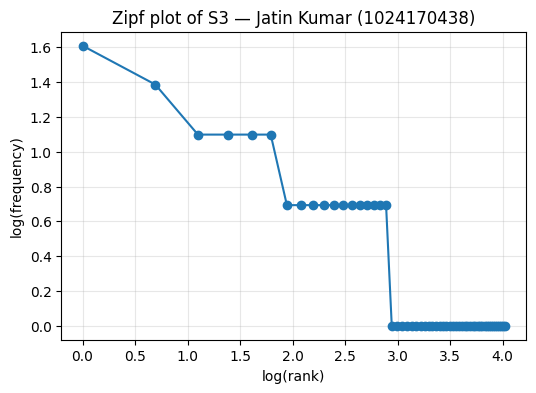


Top 5 bigrams in S1: [(('.', 'it'), 5), (('yesterday', '.'), 5), (('it', 'worked'), 3), (('worked', 'yesterday'), 3), (('the', 'printer'), 3)]
Top 5 bigrams in S3: [(('worked', 'yesterday'), 3), (('student', 'portal'), 2), (('stopped', 'syncing'), 2), (('stopped', 'responding'), 2), (('keeps', 'disconnecting'), 2)]


In [9]:
import math, numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk import bigrams

S1 = [t for r in results.values() for t in r["tokens"]]                       # all tokens
S2 = [t for t in S1 if not is_punct(t)]                                       # no punctuation
S3 = [t for r in results.values() for t in r["final"]]                        # no punctuation, no stopwords
S4 = [porter.stem(t) for t in S3]                                             # S3 after Porter

def stats(name, seq):
    n, u = len(seq), len(set(seq))
    return {"Set": name, "Tokens": n, "Unique": u, "TTR": round(u / n, 4)}

q5 = pd.DataFrame([stats("S1 (all tokens)", S1), stats("S2 (no punct)", S2),
                   stats("S3 (final)", S3), stats("S4 (S3 + Porter)", S4)])
print(q5.to_string(index=False))

print("\nTop 10 words in S1:", Counter(S1).most_common(10))
print("Top 10 words in S3:", Counter(S3).most_common(10))

# ---- Zipf plot for S3: log(rank) vs log(frequency)
freqs = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freqs) + 1)
plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(freqs), "o-")
plt.xlabel("log(rank)"); plt.ylabel("log(frequency)")
plt.title(f"Zipf plot of S3 — {NAME} ({ROLL_NO})")
plt.grid(alpha=.3); plt.show()

# ---- Top 5 bigrams (built inside each ticket so no bigram straddles two different tickets)
bg1 = Counter(b for r in results.values() for b in bigrams(r["tokens"]))
bg3 = Counter(b for r in results.values() for b in bigrams(r["final"]))
print("\nTop 5 bigrams in S1:", bg1.most_common(5))
print("Top 5 bigrams in S3:", bg3.most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR is unique tokens divided by total tokens. It went S1 0.5150, S2 0.5912, S3 0.6747, S4 0.6506.
- S1 to S2 (increase): removing the 30 punctuation tokens reduces the total from 167 to 137, but unique tokens only go from 86 to 81, since punctuation like `.` repeats a lot.
- S2 to S3 (bigger increase): removing 54 stopwords such as `the`, `it`, `is` reduces tokens from 137 to 83, while unique tokens only drop from 81 to 56.
- S3 to S4 (decrease): stemming keeps the token count at 83 but merges forms, e.g. `worked`, `working` and `works` all become `work`, so unique tokens fall from 56 to 54.

So removing repeated tokens increases TTR and stemming decreases it.

---
## 6. Interpretation

**(a) Why does TTR change from S1 to S4?** TTR went 0.5150 (S1) → 0.5912 (S2) → 0.6747 (S3) → 0.6506 (S4). Removing punctuation (S2) and stopwords (S3) deletes many repeated tokens (`.`, `the`, `it`, `is`), so the token count falls much faster than the unique count (167 → 83 tokens, 86 → 56 unique) and TTR rises. Porter stemming (S4) keeps the same 83 tokens but merges forms (`worked`, `working`, `works` → `work`), so unique tokens fall from 56 to 54 and TTR drops a little.

**(b) Example where `word_tokenize()` and my tokenizer differ:** In ticket T14, "The printer won't print; it isn't jammed.", `word_tokenize` gives `wo`, `n't`, `is`, `n't`, but `my_tokenize` gives `won't` and `isn't`. `word_tokenize` follows Penn Treebank rules and splits a contraction into the word and the negation, while my pattern allows an apostrophe inside a word, so the contraction stays as one token. Another example is the email `it.helpdesk@thapar.edu`, which `word_tokenize` cuts at `@`.

**(c) Undesirable stemming:** Porter changes `several` to `sever` (it now looks like the word *severe*), and Lancaster changes `campus` to `camp`, which has a different meaning. My Regexp stemmer gives `stopp` for `stopped`, which is not a real word.

**(d) Where POS-aware lemmatization keeps the meaning better:** `tried` (tagged as a verb) becomes `try` with the lemmatizer, but Porter gives `tri`, which is not a word and does not match `try`. In the same way `stopped → stop` and `jammed → jam` come out correctly with the lemmatizer, while the Regexp stemmer gives `stopp` and `jamm`.